# Real-to-Sim Sensor Model, Part 3: The Dataset
| Part | Notebook | What it does |
|---|---|---|
| 1 | `12_1_real2sim_render` | Camera, real camera poses, CAD → 7 input maps per pixel |
| 2 | `12_2_real2sim_labels` | Correct the CAD pose, then `y_drop` and `e_z` for every CAD pixel |
| **3** | **`12_3_real2sim_dataset`** | **All views of all workpieces → one table: inputs + labels per pixel** |
| 4–6 | | Model, simulator, export |

**What this notebook does**
1. **Builds the dataset.** For every real view (288 per workpiece × 4 workpieces), every CAD pixel becomes one row: its inputs (what the CAD and the camera pose say about that pixel) and its labels (what the real sensor did there). The labels use the corrected pose and the rule from 12_2.
2. **Adds three new inputs**, `edge_mm`, `deeper_mm` and `closer_mm`. Section 2 shows why the 7 inputs of Part 1 are not enough, and section 4 tests that the new ones help on a workpiece the test has never seen.

All 10 inputs come from the CAD and the camera pose alone, never from the real scan. That is what lets the simulator (Part 5) compute them for any new viewpoint.

**Output**: `simulation/real2sim/test_11_real_pocket/{workpiece}/dataset_960x540.npz`, loaded with `rs.load_dataset(...)`.

In [1]:
# ==========================================
# CONFIGURATION
# ==========================================
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import real2sim as rs

EXPERIMENT = "test_11_real_pocket"
ALL_WORKPIECES = ["TH1021AV", "TH1031AV", "TH1041AV", "TH1051AV"]
GRID_SCALE = 2          # 960x540 working grid (12_1 section 7)
GATE_MM = 10.0          # same pairing rule as 12_2
REBUILD = False         # True: rebuild the dataset files even if they exist (about 1 min per workpiece)
EXAMPLE = ("TH1041AV", 100)   # view used for the maps in section 2

FIG_DIR = f"simulation/real2sim/{EXPERIMENT}"
cam = rs.Camera.native().downscaled(GRID_SCALE)
print(f"Grid {cam.width}x{cam.height}")
print(f"Inputs ({len(rs.INPUT_NAMES)}): {rs.INPUT_NAMES}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Grid 960x540
Inputs (10): ['xn', 'yn', 'z', 'nx', 'ny', 'nz', 'theta_inc', 'edge_mm', 'deeper_mm', 'closer_mm']


## 1. Build the dataset
For each view: render the CAD with the corrected pose (`T_cad_refined.npy` from 12_2), compute the 10 inputs, make the labels with `rs.make_labels` (same as 12_2 section 8), and keep the CAD pixels only. One file per workpiece.

| Column | Meaning |
|---|---|
| `workpiece`, `view`, `u`, `v` | where the row comes from (pixel `u` right, `v` down on the 960×540 grid) |
| `xn` … `theta_inc` | the 7 inputs of Part 1 |
| `edge_mm`, `deeper_mm`, `closer_mm` | the 3 new inputs (section 2) |
| `y_drop` | 1 = the sensor returned nothing at this pixel |
| `e_z` | real depth − CAD depth (mm); empty where `y_drop = 1` |
| `edge_dx_mm`, `edge_dy_mm`, `n_pts` | extras, not model inputs: direction to the nearest edge, number of real points in the pixel |

In [2]:
# ==========================================
# 1. BUILD (or load) THE DATASET
# ==========================================
for wp in ALL_WORKPIECES:
    path = rs.dataset_path(EXPERIMENT, wp, cam)
    if REBUILD or not os.path.exists(path):
        t0 = time.time()
        rs.build_dataset(EXPERIMENT, wp, cam, gate_mm=GATE_MM)
        print(f"{wp}: built in {time.time() - t0:.0f} s -> {path}")

df = rs.load_dataset(EXPERIMENT, ALL_WORKPIECES, cam)
df["dataset_file_MB"] = 0.0
size = {wp: os.path.getsize(rs.dataset_path(EXPERIMENT, wp, cam)) / 1e6 for wp in ALL_WORKPIECES}
on_border = (df.u == 0) | (df.u == cam.width - 1) | (df.v == 0) | (df.v == cam.height - 1)
summary = df.groupby("workpiece", observed=True).agg(
    views=("view", "nunique"), pixels=("y_drop", "size"), dropped=("y_drop", "mean"),
    ez_median=("e_z", "median"), ez_p10=("e_z", lambda s: s.quantile(0.1)), ez_p90=("e_z", lambda s: s.quantile(0.9)))
summary["pixels_per_view"] = summary.pixels / summary.views
summary["file_MB"] = pd.Series(size)
summary["views_cut_by_image_border"] = df[on_border].groupby("workpiece", observed=True).view.nunique()
df = df.drop(columns="dataset_file_MB")
print(f"{len(df):,} rows (CAD pixels) from {df.groupby(['workpiece', 'view'], observed=True).ngroups} views | "
      f"dropped {df.y_drop.mean() * 100:.1f}% | e_z median {df.e_z.median():+.2f} mm")
display(summary.fillna(0).round(3))

11,769,758 rows (CAD pixels) from 1152 views | dropped 23.3% | e_z median +0.52 mm


,views,pixels,dropped,ez_median,ez_p10,ez_p90,pixels_per_view,file_MB,views_cut_by_image_border
workpiece,,,,,,,,,
TH1021AV,288,2925687,0.238,0.515,-3.443,5.534,10158.635,73.510,0.0
TH1031AV,288,2975996,0.247,0.531,-3.061,5.289,10333.319,74.633,0.0
TH1041AV,288,2916099,0.225,0.525,-2.966,5.101,10125.344,72.829,0.0
TH1051AV,288,2951976,0.221,0.522,-2.612,4.892,10249.917,75.289,0.0


## 2. The three new inputs
Two pixels can have identical Part 1 inputs (same depth, same normal, same angle) and still behave completely differently, because the sensor looks at a small **neighbourhood**, not a single point. Near a depth step it blends the two levels. So the model needs to know what is around each pixel:

| Input | Meaning | Example on this workpiece |
|---|---|---|
| `edge_mm` | distance to the nearest CAD edge (outline, crease or depth step), in mm | 0 on every edge, ~20 mm in the middle of the top face |
| `deeper_mm` | how much **deeper** the scene gets within 5 mm around the pixel (a drop-off nearby) | top face next to the outer edge (~40 mm drop to the table) or the pocket rim (15 mm) |
| `closer_mm` | how much **closer** the scene gets within 5 mm (a rise nearby) | pocket floor next to the pocket walls (15 mm) |

The scene here is the CAD **plus the table** (the plane z = 0, exact after 12_2's correction), so the bottom of a wall is not mistaken for a drop-off. The 5 mm radius was the best of 2–12 mm in tests like section 4.

**The maps below** (one view, nearly straight down): compare the **top-face rim** with the **pocket floor along its walls**. They have the same angle (top right), but the top face next to a drop-off reads **too far** (red in `e_z`) and is often dropped, while the pocket floor next to a rise reads **too close** (blue). `edge_mm` says both are near an edge; only `deeper_mm` / `closer_mm` tell them apart.

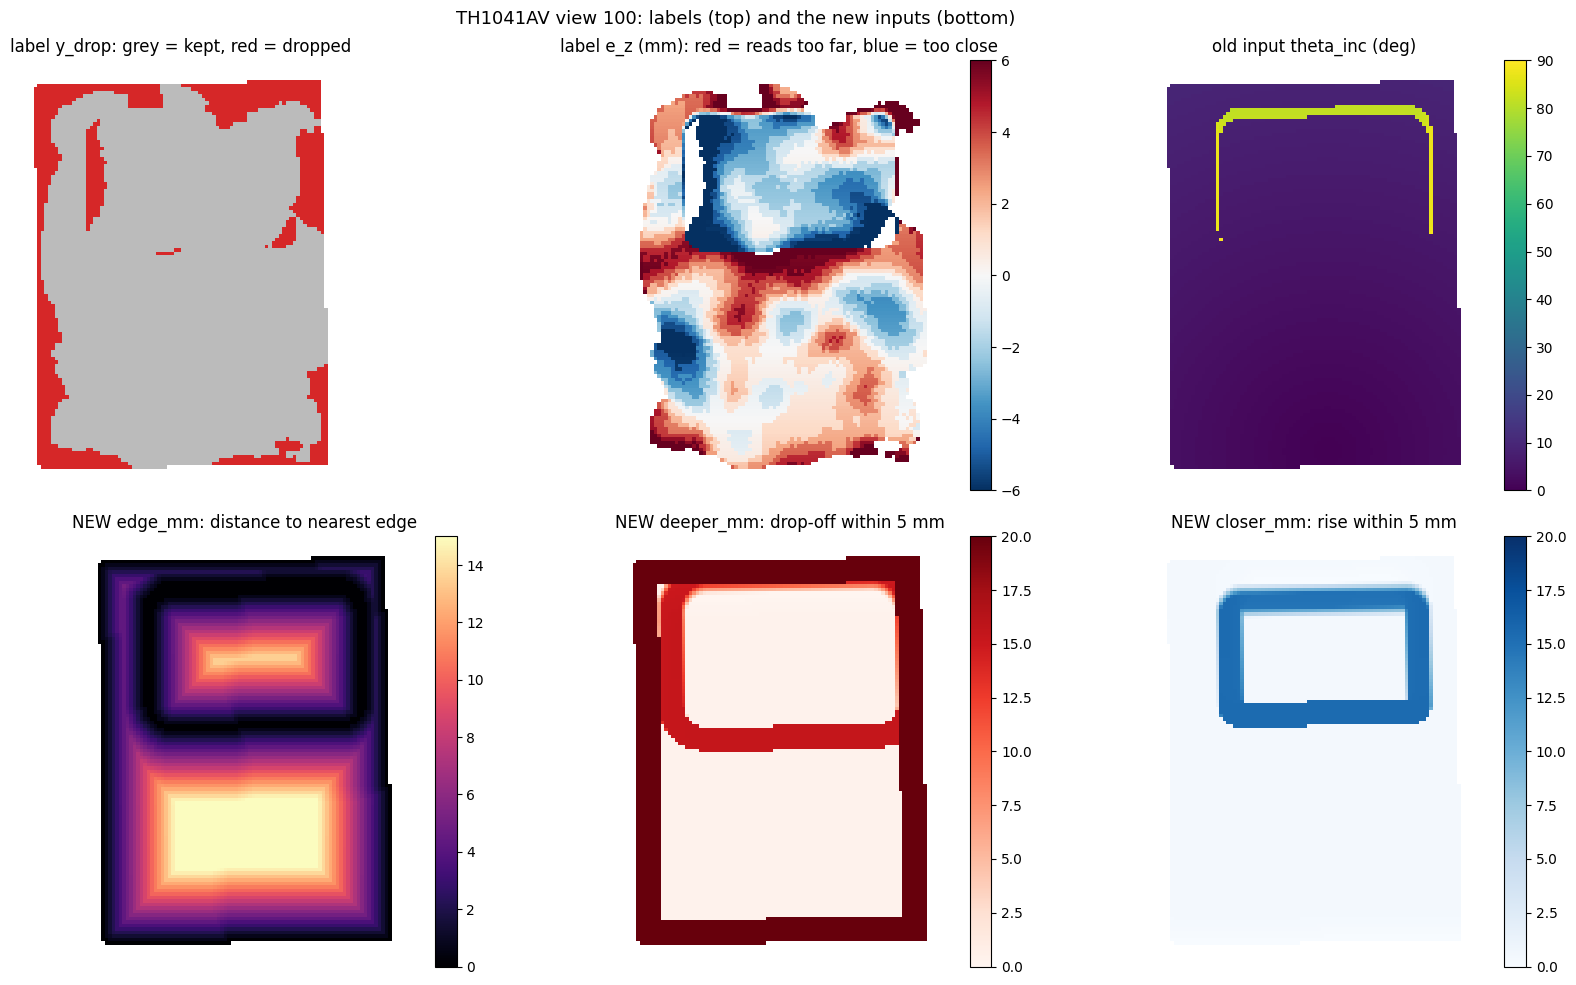

In [3]:
# ==========================================
# 2. THE NEW INPUTS ON ONE VIEW
# ==========================================
wp, v = EXAMPLE
d = rs.real_dirs(EXPERIMENT, wp)
r, L, ctx, _ = rs.view_maps(cam, rs.CadRenderer(d["cad"]), d["raw"], v, rs.load_cad_pose(EXPERIMENT, wp), GATE_MM)
b0, b1, a0, a1 = rs.mask_bbox(r["mask"], margin=6)
crop = (slice(b0, b1), slice(a0, a1))

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
panels = [  # (axis, image, colormap, vmin, vmax, title)
    (axes[0, 0], L["y_drop"], ListedColormap(["#bbbbbb", "#d62728"]), 0, 1, "label y_drop: grey = kept, red = dropped"),
    (axes[0, 1], L["e_z"], "RdBu_r", -6, 6, "label e_z (mm): red = reads too far, blue = too close"),
    (axes[0, 2], r["theta_inc"], "viridis", 0, 90, "old input theta_inc (deg)"),
    (axes[1, 0], ctx["edge_mm"], "magma", 0, 15, "NEW edge_mm: distance to nearest edge"),
    (axes[1, 1], ctx["deeper_mm"], "Reds", 0, 20, "NEW deeper_mm: drop-off within 5 mm"),
    (axes[1, 2], ctx["closer_mm"], "Blues", 0, 20, "NEW closer_mm: rise within 5 mm"),
]
for ax, img, cmap, lo, hi, title in panels:
    im = ax.imshow(img[crop], cmap=cmap, vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
    if ax is not axes[0, 0]:
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle(f"{wp} view {v}: labels (top) and the new inputs (bottom)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part3_new_inputs_example.png"), dpi=110)
plt.show()

## 3. What the sensor does next to a step (all views)
The same comparison over the whole dataset, for surfaces facing the camera (angle < 40°, so top faces and the pocket floor, not walls), grouped by what is within 5 mm:
- **drop-off nearby** (`deeper_mm` > 5): e.g. the top face at its edges
- **rise nearby** (`closer_mm` > 5): e.g. the pocket floor along its walls
- **flat surroundings** (both ≤ 5)

**Left:** how often the pixel is dropped. **Right:** the median depth error of the kept pixels. If the three curves were the same, `deeper_mm` / `closer_mm` would be useless; the further apart they are, the more the model needs them.

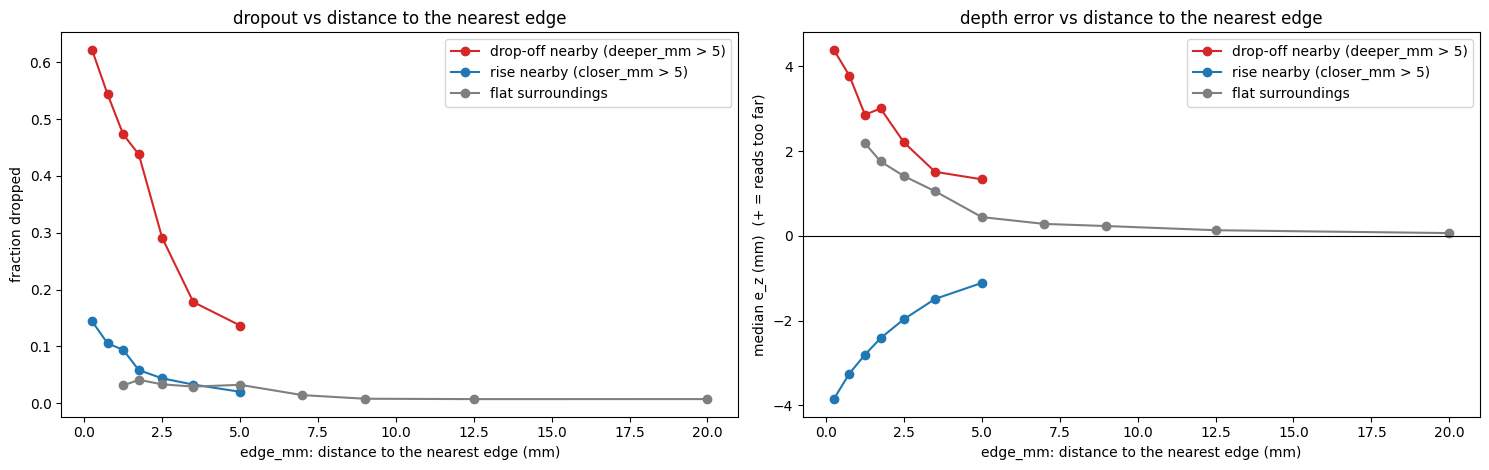

                                  pixels  dropped  ez_median
surroundings                                                
both                                 135    0.207     -5.438
drop-off nearby (deeper_mm > 5)  3456466    0.423      2.576
flat surroundings                4887171    0.015      0.249
rise nearby (closer_mm > 5)      1178213    0.076     -2.332

Extra (not a model input yet): dropout within 2 mm of an edge, by where that edge is in the image
              pixels  dropped
above/below  3385935    0.440
left          609074    0.463
right         569457    0.356


In [4]:
# ==========================================
# 3. DROPOUT AND DEPTH ERROR NEXT TO A STEP
# ==========================================
face = df[df.theta_inc < 40].copy()
face["surroundings"] = np.select(
    [(face.deeper_mm > 5) & (face.closer_mm <= 5), (face.closer_mm > 5) & (face.deeper_mm <= 5),
     (face.deeper_mm <= 5) & (face.closer_mm <= 5)],
    ["drop-off nearby (deeper_mm > 5)", "rise nearby (closer_mm > 5)", "flat surroundings"], "both")
edge_bins = np.array([0, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 10, 15, 25])
face["edge_bin"] = pd.cut(face.edge_mm, edge_bins, include_lowest=True)
x = 0.5 * (edge_bins[:-1] + edge_bins[1:])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for name, color in [("drop-off nearby (deeper_mm > 5)", "#d62728"), ("rise nearby (closer_mm > 5)", "#1f77b4"),
                    ("flat surroundings", "#7f7f7f")]:
    g = face[face.surroundings == name].groupby("edge_bin", observed=False)
    n = g.size()
    ok = (n > 2000).values
    axes[0].plot(x[ok], g.y_drop.mean().values[ok], "o-", color=color, label=name)
    axes[1].plot(x[ok], g.e_z.median().values[ok], "o-", color=color, label=name)
axes[0].set_ylabel("fraction dropped")
axes[0].set_title("dropout vs distance to the nearest edge")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_ylabel("median e_z (mm)  (+ = reads too far)")
axes[1].set_title("depth error vs distance to the nearest edge")
for ax in axes:
    ax.set_xlabel("edge_mm: distance to the nearest edge (mm)")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part3_step_effect.png"), dpi=110)
plt.show()

print(face.groupby("surroundings").agg(pixels=("y_drop", "size"), dropped=("y_drop", "mean"),
                                       ez_median=("e_z", "median")).round(3))
near = df[df.edge_mm < 2]
side = np.where(near.edge_dx_mm.abs() > near.edge_dy_mm.abs(), np.where(near.edge_dx_mm < 0, "left", "right"), "above/below")
print("\nExtra (not a model input yet): dropout within 2 mm of an edge, by where that edge is in the image")
print(near.groupby(side).y_drop.agg(["size", "mean"]).rename(columns={"size": "pixels", "mean": "dropped"}).round(3))

## 4. Do the new inputs help on an unseen workpiece?
A quick stand-in for the model, **not** the model itself (that is Part 4). Cut every input into a few ranges and, for each combination of ranges, take the average label of the training pixels: the dropout rate and the median `e_z`. Then predict a **workpiece that was left out** with this lookup table. This is repeated four times (each workpiece left out once) and averaged.

If adding an input makes the left-out predictions better, that input carries real, transferable information about the sensor, not something specific to one workpiece.

| Score | Meaning |
|---|---|
| `e_z MAE (mm)` | average size of the depth error the lookup table gets wrong, on kept pixels. Lower is better. |
| `dropout BCE` | the same loss Part 4 trains with: how surprised the table is by what the sensor really did (dropped or kept). Lower is better. |

,e_z MAE (mm),dropout BCE
inputs,,
nothing (one average for every pixel),2.488,0.543
Part 1 inputs: angle + distance,2.458,0.494
+ edge_mm,2.396,0.374
+ edge_mm + deeper_mm + closer_mm,2.004,0.285


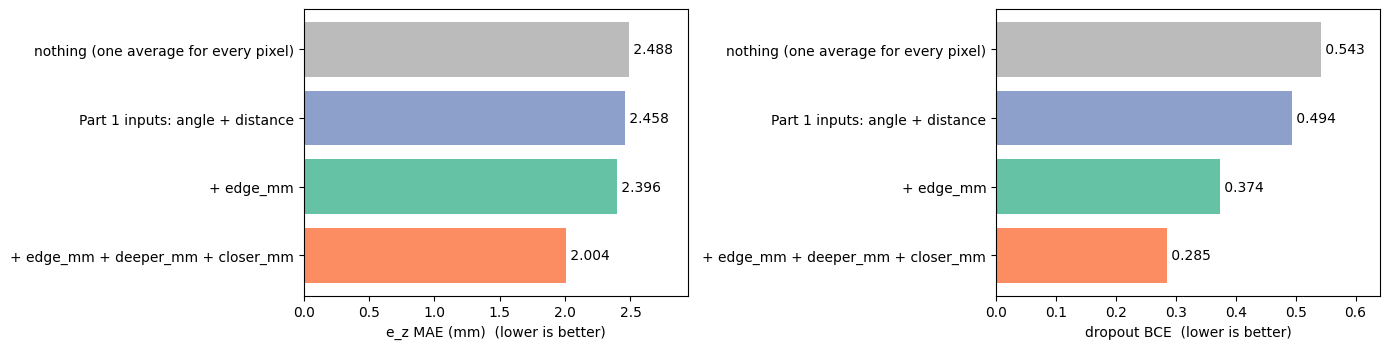

In [5]:
# ==========================================
# 4. LEAVE-ONE-WORKPIECE-OUT TEST OF THE INPUTS
# ==========================================
B = pd.DataFrame(dict(
    workpiece=df.workpiece, y_drop=df.y_drop, e_z=df.e_z,
    angle=pd.cut(df.theta_inc, [0, 10, 20, 30, 40, 55, 70, 80, 90], include_lowest=True).cat.codes,
    distance=pd.cut(df.z, [0, 450, 500, 550, 2000]).cat.codes,
    edge=pd.cut(df.edge_mm, [0, 1, 2, 3, 4, 6, 10, 1e3], include_lowest=True).cat.codes,
    deeper=pd.cut(df.deeper_mm, [-1, 2, 5, 10, 20, 100]).cat.codes,
    closer=pd.cut(df.closer_mm, [-1, 2, 5, 10, 20, 100]).cat.codes))


def lookup_score(keys):
    scores = []
    for test in ALL_WORKPIECES:
        train, held = B[B.workpiece != test], B[B.workpiece == test]
        if keys:
            g = train.groupby(keys)
            held = held.join(g.e_z.median().rename("pz"), on=keys).join(g.y_drop.mean().rename("pd"), on=keys)
        else:
            held = held.assign(pz=np.nan, pd=np.nan)
        pz = held.pz.fillna(train.e_z.median())
        p = held.pd.fillna(train.y_drop.mean()).clip(1e-3, 1 - 1e-3)
        kept = held.e_z.notna()
        scores.append(((held.e_z[kept] - pz[kept]).abs().mean(),
                       -(held.y_drop * np.log(p) + (1 - held.y_drop) * np.log(1 - p)).mean()))
    return np.mean(scores, axis=0)


tests = [("nothing (one average for every pixel)", []),
         ("Part 1 inputs: angle + distance", ["angle", "distance"]),
         ("+ edge_mm", ["angle", "distance", "edge"]),
         ("+ edge_mm + deeper_mm + closer_mm", ["angle", "distance", "edge", "deeper", "closer"])]
res = pd.DataFrame([(name, *lookup_score(keys)) for name, keys in tests],
                   columns=["inputs", "e_z MAE (mm)", "dropout BCE"]).set_index("inputs")
display(res.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, col in zip(axes, res.columns):
    ax.barh(range(len(res)), res[col], color=["#bbbbbb", "#8da0cb", "#66c2a5", "#fc8d62"])
    ax.set_yticks(range(len(res)))
    ax.set_yticklabels(res.index)
    ax.invert_yaxis()
    ax.set_xlabel(col + "  (lower is better)")
    for i, val in enumerate(res[col]):
        ax.text(val, i, f" {val:.3f}", va="center")
    ax.set_xlim(0, res[col].max() * 1.18)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part3_input_test.png"), dpi=110)
plt.show()

## 5. What the dataset covers
A model is only trustworthy for inputs it has seen. These are the ranges in the real data; the simulator should be used inside them (or with care outside).

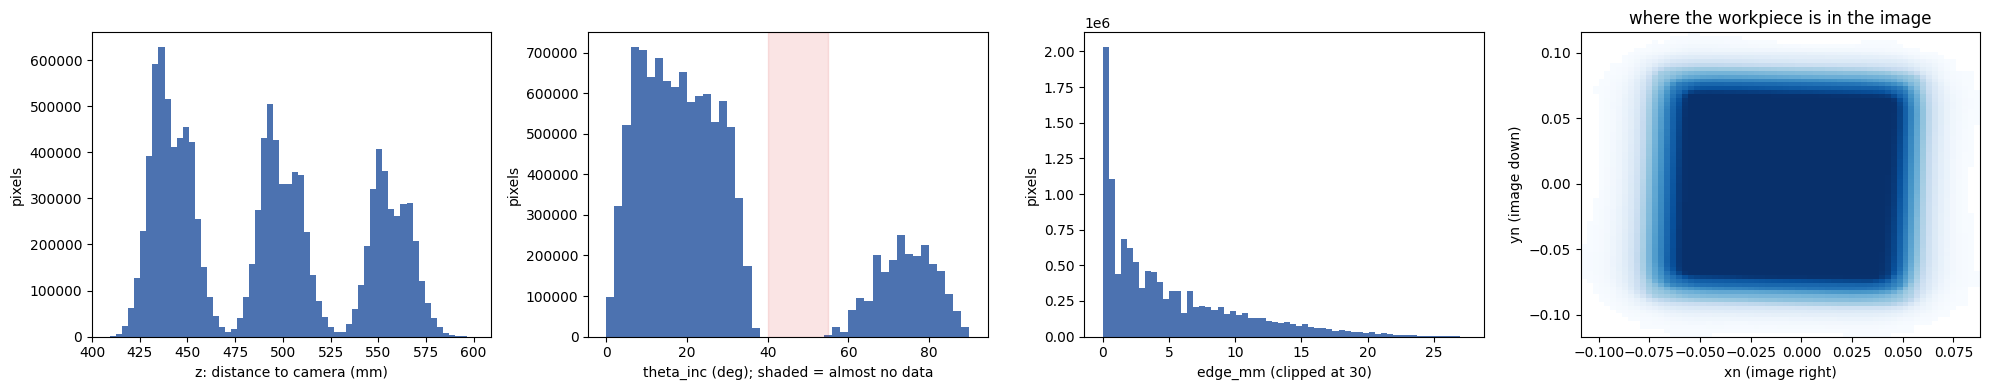

,1%,median,99%
z,422.992,491.948,575.332
theta_inc,2.180,21.009,85.394
xn,-0.080,-0.008,0.064
yn,-0.091,-0.001,0.090
edge_mm,0.000,3.260,20.594
deeper_mm,0.351,3.107,50.000
closer_mm,0.276,1.977,28.698


Pixels with theta_inc in 40-55 deg: 0.00%


In [6]:
# ==========================================
# 5. COVERAGE OF THE INPUTS
# ==========================================
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].hist(df.z, bins=60, color="#4C72B0")
axes[0].set_xlabel("z: distance to camera (mm)")
axes[1].hist(df.theta_inc, bins=np.arange(0, 91, 2), color="#4C72B0")
axes[1].axvspan(40, 55, color="#d62728", alpha=0.12)
axes[1].set_xlabel("theta_inc (deg); shaded = almost no data")
axes[2].hist(df.edge_mm.clip(upper=30), bins=60, color="#4C72B0")
axes[2].set_xlabel("edge_mm (clipped at 30)")
pix_bins = [np.arange(df.xn.min() - 0.5 / cam.fx, df.xn.max() + 2 / cam.fx, 2 / cam.fx),   # 2 pixels per bin
            np.arange(df.yn.min() - 0.5 / cam.fy, df.yn.max() + 2 / cam.fy, 2 / cam.fy)]
axes[3].hist2d(df.xn, df.yn, bins=pix_bins, cmap="Blues", cmin=1)
axes[3].set_xlabel("xn (image right)")
axes[3].set_ylabel("yn (image down)")
axes[3].set_title("where the workpiece is in the image")
for ax in axes[:3]:
    ax.set_ylabel("pixels")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part3_coverage.png"), dpi=110)
plt.show()

q = df[["z", "theta_inc", "xn", "yn", "edge_mm", "deeper_mm", "closer_mm"]].quantile([0.01, 0.5, 0.99]).T
q.columns = ["1%", "median", "99%"]
display(q.round(3))
print(f"Pixels with theta_inc in 40-55 deg: {((df.theta_inc > 40) & (df.theta_inc < 55)).mean() * 100:.2f}%")

## Summary of Part 3 (results on test_11_real_pocket)
### Must understand
- **The dataset**: one row per CAD pixel per view, 1152 views (288 × 4 workpieces), **11.8 million rows** (~10,000 per view). Each row has 10 inputs (from the CAD and camera pose only) and 2 labels (from the real scan, 12_2's rule with the corrected pose). Overall 23% of pixels are dropped and `e_z` has median +0.5 mm, 10–90% about −3 to +5.5 mm, nearly the same on all four workpieces.
- **Three new inputs**, because the sensor looks at a neighbourhood and smooths depth across steps:
  - next to a **drop-off** (`deeper_mm` > 5, e.g. top face at its edges): 42% dropped, reads **+2.6 mm too far** (62% and +4.4 mm right at the edge);
  - next to a **rise** (`closer_mm` > 5, e.g. pocket floor along its walls): 8% dropped, reads **−2.3 mm too close**;
  - **flat surroundings**: 1.5% dropped, +0.25 mm.

  `edge_mm` alone says "near an edge" but cannot tell a drop-off from a rise, which have opposite errors.
- **They carry real information** (section 4, workpiece left out): dropout BCE 0.494 → 0.374 with `edge_mm` → **0.285** with all three; `e_z` error 2.46 → 2.40 → **2.00 mm**. The Part 1 inputs alone barely beat a single average.
- **What the data covers** (the model is only trustworthy inside this): distance 423–575 mm (three rings of views around 440 / 500 / 555 mm); angle 0–40° and 55–90°, **nothing in 40–55°**; the workpiece always sits near the image centre (|xn|, |yn| < 0.1), so the model learns nothing about the image corners. That is fine as long as the simulated views also centre the workpiece.
- **What no input can predict**: the `e_z` map in section 2 has smooth blobs of ±4–6 mm on flat areas far from any edge. They are why the lookup table still misses by ~2 mm. The model will treat them as spread (σ), and Part 5's blurred noise has to reproduce their blob shape; Part 5 measures their size.

### Know what it does
- `rs.build_dataset` / `rs.load_dataset`: build and load `{workpiece}/dataset_960x540.npz` (~74 MB each). Built once (~80 s per workpiece); `REBUILD = True` redoes it.
- `deeper_mm` / `closer_mm` look at the CAD **plus the table** (plane z = 0) within 5 mm (best of 2–12 mm), so a wall's foot on the table is not a drop-off.
- Extra columns, not inputs yet: `edge_dx_mm`, `edge_dy_mm` (direction to the nearest edge). Within 2 mm of an edge, pixels whose edge is to their **left** drop 46%, to their **right** 36%, the usual one-sided shadow of a stereo camera. Part 4 can test whether adding the direction helps.

### Next (Part 4, model)
Split **by workpiece**, as in section 4: the 288 views of one workpiece overlap heavily, so a random split of pixels or views would let the model see its test answers. Train on three workpieces, test on the fourth.